<a href="https://colab.research.google.com/github/macontreras04/cpf/blob/main/CQF_Exam3_SPY_GBM_Full_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CQF Exam 3 — Machine Learning  
## Predicting Positive Market Moves with Gradient Boosting

**Ticker selected:** SPY ETF  
**Task:** Short-term uptrend prediction using binomial classification  
**Target labels:** `[0, 1]`  
**Near-zero return treatment:** returns inside ±0.02% are removed from supervised training and evaluation  
**Final models:** Classic Gradient Boosting, XGBoost, and LightGBM  

This notebook is designed as the computational appendix to the analytical PDF report. The report should be the primary submitted document, while this notebook provides reproducible code, outputs, and supporting evidence.

# Question A — Entropy in Classification

Entropy measures the degree of class impurity in a node or partition. For binary classification, entropy is:

$$
H(S) = -p_1 \log_2(p_1) - p_0 \log_2(p_0)
$$

where $p_1$ is the proportion of positive observations and $p_{0}$ is the proportion of negative observations.

A pure node has observations from only one class; therefore one of the probabilities is 1 and the other is 0, making entropy equal to zero. A highly mixed node has both classes represented in similar proportions and therefore has high entropy.

**Answer A(a):** High entropy means the partitions are pure.  
**False.** High entropy means high uncertainty and high class mixture.

**Answer A(b):** High entropy means the partitions are impure.  
**True.** High entropy indicates that the node contains a mixture of classes and is therefore less informative for classification.

# Question B — Feature Selection Using the Funnelling Approach

The feature-selection process follows a three-stage funnel:

1. **Filter methods:** remove unusable, unstable, or redundant variables before model fitting.  
2. **Wrapper methods:** evaluate feature subsets using a predictive model and time-series cross-validation.  
3. **Embedded methods:** use the trained gradient boosting models' internal feature importance to retain the most relevant variables.

This is consistent with a practical machine-learning workflow: start broad, remove clearly weak features, then allow model-based procedures to identify features that add predictive value.

## Imports

The notebook uses only standard data science libraries plus `xgboost`, `lightgbm`, and `yfinance`.

If needed, run:

```bash
pip install yfinance pandas numpy matplotlib scikit-learn xgboost lightgbm
```

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import yfinance as yf

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
)
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

## Configuration

The exam asks for binomial classification with labels `[0, 1]`. This notebook defines:

$$
y_t =
\begin{cases}
1, & r_{t+1} > 0.0002 \\
0, & r_{t+1} < -0.0002 \\
\text{NaN}, & \text{otherwise}
\end{cases}
$$

where $0.0002 = 0.02\%$.

The 0.02% threshold removes extremely small near-zero movements while retaining most economically observable daily moves.

In [ ]:
TICKER = "SPY"

START_DATE = "2010-01-01"
END_DATE = "2026-04-01"      # exclusive end date; includes 2026Q1

DEV_END = "2025-12-31"
OOS_START = "2026-01-01"
OOS_END = "2026-03-31"

THRESHOLD = 0.0002           # 0.02%
RANDOM_STATE = 42

CORRELATION_CUTOFF = 0.90
MAX_FEATURES_AFTER_FUNNEL = 25

OUTPUT_PREFIX = "cqf_exam3_spy_gbm"

# 1. Data Collection

SPY is selected because it is a liquid ETF tracking the S&P 500. Its liquidity, long historical record, and strong market relevance make it suitable for a short-term equity-index trend prediction exercise.

In [ ]:
raw = yf.download(TICKER, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)

if raw.empty:
    raise RuntimeError("No data downloaded. Check internet connection or Yahoo Finance access.")

if isinstance(raw.columns, pd.MultiIndex):
    raw = raw.xs(TICKER, axis=1, level=1)

raw = raw.rename(columns=str.title)
raw.index = pd.to_datetime(raw.index)
raw = raw.sort_index()

required = ["Open", "High", "Low", "Close", "Volume"]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise RuntimeError(f"Missing required columns: {missing}")

df0 = raw[required].copy()

print(f"Rows downloaded: {len(df0)}")
print(f"Date range: {df0.index.min().date()} to {df0.index.max().date()}")
df0.head()

Rows downloaded: 4085
Date range: 2010-01-04 to 2026-03-31


Price,Open,High,Low,Close,Volume
Date,,,,,
2010-01-04,84.078076,84.841263,83.434602,84.796371,118944600
2010-01-05,84.744034,85.058288,84.437259,85.020874,111579900
2010-01-06,84.938516,85.290183,84.871179,85.080681,116074400
2010-01-07,84.923573,85.544601,84.684141,85.439850,131091100
2010-01-08,85.215373,85.761580,85.043285,85.724167,126402800


# 2. Initial Exploratory Data Analysis

This section checks the raw data, missing values, descriptive statistics, price path, and daily return distribution.

In [ ]:
df0.describe().T

,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
Open,4085.0,2.741514e+02,1.622487e+02,7.783578e+01,1.488321e+02,2.323312e+02,3.908294e+02,6.951515e+02
High,4085.0,2.756212e+02,1.630721e+02,7.806979e+01,1.492869e+02,2.344079e+02,3.930631e+02,6.959394e+02
Low,4085.0,2.725436e+02,1.613173e+02,7.634113e+01,1.480286e+02,2.303042e+02,3.887985e+02,6.920500e+02
Close,4085.0,2.741956e+02,1.622587e+02,7.714883e+01,1.485884e+02,2.325044e+02,3.909311e+02,6.935958e+02
Volume,4085.0,1.090620e+08,6.755195e+07,2.027000e+07,6.540920e+07,8.935190e+07,1.322564e+08,7.178287e+08


In [ ]:
df0.isnull().sum()

Price
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

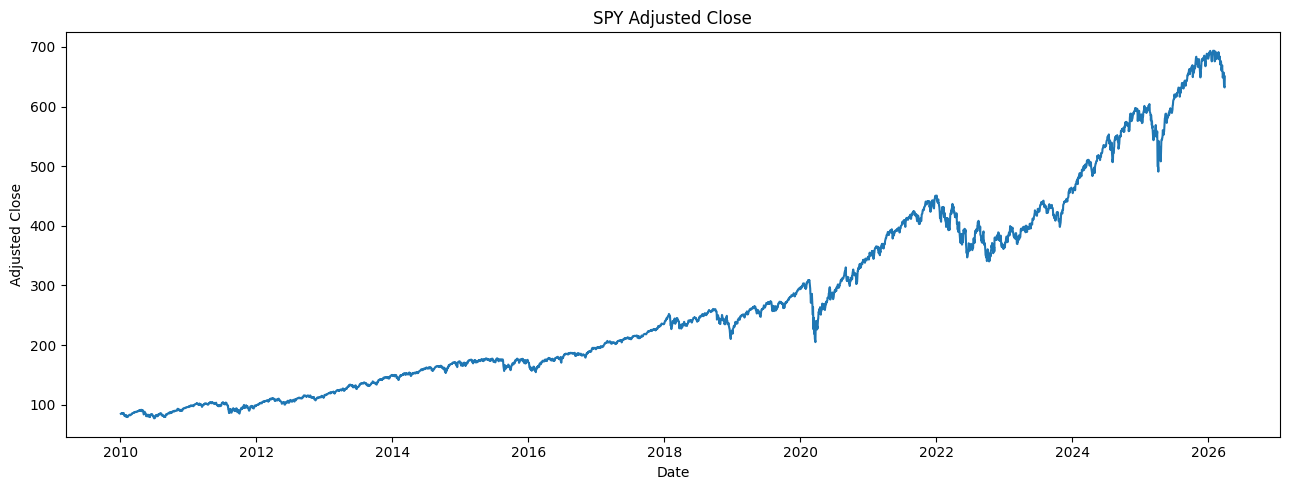

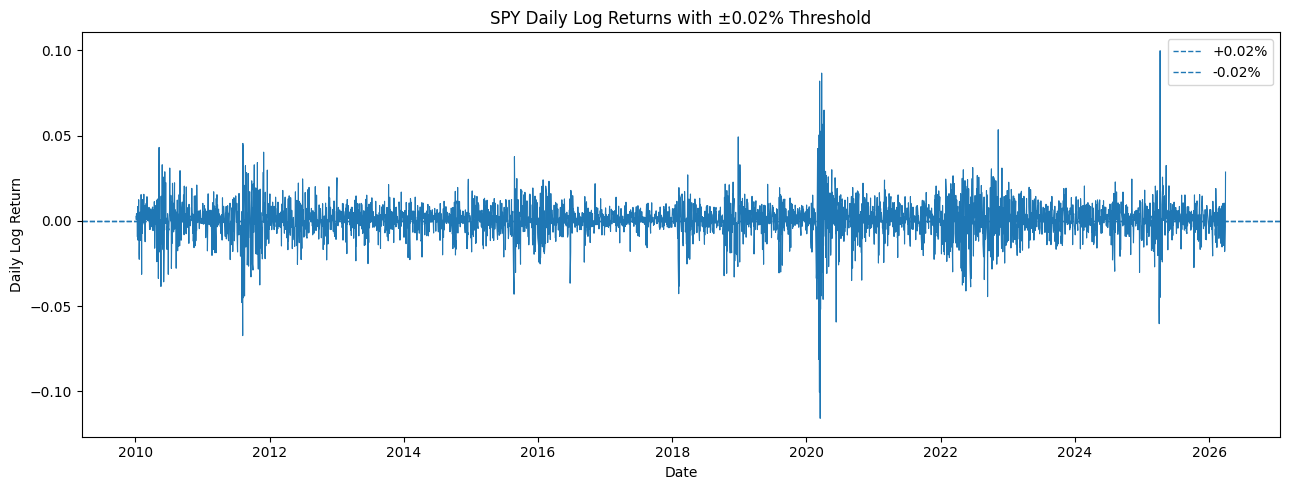

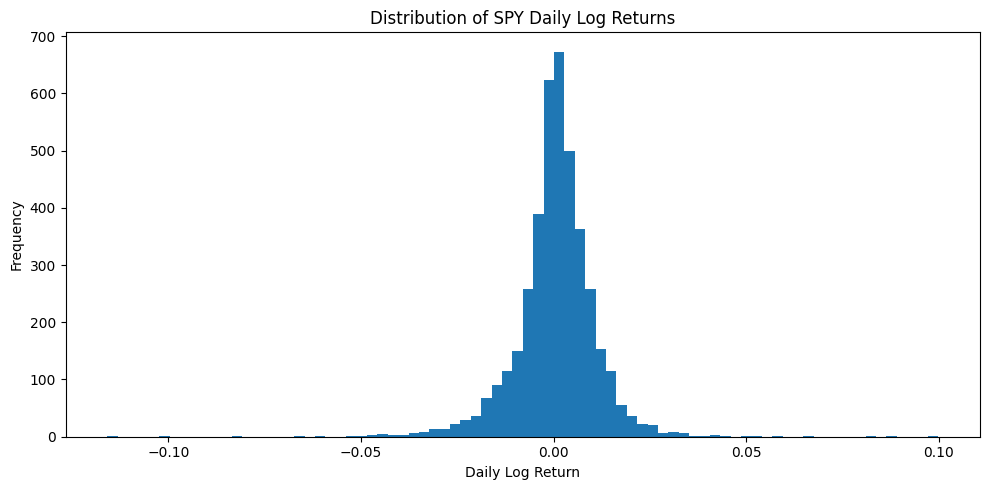

In [ ]:
tmp = df0.copy()
tmp["log_return"] = np.log(tmp["Close"]).diff()

plt.figure(figsize=(13, 5))
plt.plot(tmp.index, tmp["Close"])
plt.title("SPY Adjusted Close")
plt.xlabel("Date")
plt.ylabel("Adjusted Close")
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 5))
plt.plot(tmp.index, tmp["log_return"], linewidth=0.8)
plt.axhline(THRESHOLD, linestyle="--", linewidth=1, label="+0.02%")
plt.axhline(-THRESHOLD, linestyle="--", linewidth=1, label="-0.02%")
plt.title("SPY Daily Log Returns with ±0.02% Threshold")
plt.xlabel("Date")
plt.ylabel("Daily Log Return")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(tmp["log_return"].dropna(), bins=80)
plt.title("Distribution of SPY Daily Log Returns")
plt.xlabel("Daily Log Return")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 3. Feature Engineering

The features are designed to capture several types of market information:

- **Lagged returns:** short-term autocorrelation and reversal effects.
- **Momentum:** cumulative price pressure across multiple horizons.
- **Trend:** distance from moving averages.
- **Volatility:** realized and high-low volatility.
- **Volume:** abnormal volume and volume shocks.
- **Calendar effects:** day-of-week and month effects.
- **Cross-asset proxies:** VIX, Treasury yield proxy, dollar ETF, long-duration Treasury ETF, high-yield credit ETF, gold ETF, and oil ETF.

All predictive features are lagged to reduce look-ahead bias.

In [ ]:
def compute_rsi(close, window=14):
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.shift(1).rolling(window).mean()
    avg_loss = loss.shift(1).rolling(window).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    return 100 - (100 / (1 + rs))

df = df0.copy()

df["log_close"] = np.log(df["Close"])
df["log_return"] = df["log_close"].diff()
df["simple_return"] = df["Close"].pct_change()

# Forward return is the object being predicted.
df["fwd_log_return"] = df["log_return"].shift(-1)
df["fwd_simple_return"] = df["simple_return"].shift(-1)

# Exam-compliant binomial label [0, 1].
df["target"] = np.where(
    df["fwd_log_return"] > THRESHOLD, 1,
    np.where(df["fwd_log_return"] < -THRESHOLD, 0, np.nan)
)

# Lagged returns.
for lag in range(1, 11):
    df[f"ret_lag_{lag}"] = df["log_return"].shift(lag)

# Rolling return sums and rolling volatilities inspired by the class example.
for w in range(10, 65, 5):
    df[f"ret_sum_{w}"] = df["log_return"].shift(1).rolling(w).sum()
    df[f"std_{w}"] = df["log_return"].shift(1).rolling(w).std()

# Momentum.
for w in [5, 10, 20, 60, 126, 252]:
    df[f"mom_{w}d"] = df["Close"].shift(1) / df["Close"].shift(1 + w) - 1

# Trend / moving average distance.
for w in [10, 20, 50, 100, 200]:
    sma = df["Close"].shift(1).rolling(w).mean()
    df[f"close_to_sma_{w}"] = df["Close"].shift(1) / sma - 1

df["sma_50_200_ratio"] = (
    df["Close"].shift(1).rolling(50).mean()
    / df["Close"].shift(1).rolling(200).mean()
    - 1
)

# Realized volatility.
for w in [5, 10, 20, 60]:
    df[f"realized_vol_{w}d"] = df["log_return"].shift(1).rolling(w).std() * np.sqrt(252)

# Parkinson volatility.
hl = np.log(df["High"] / df["Low"])
for w in [10, 20]:
    df[f"parkinson_vol_{w}d"] = (
        hl.shift(1).pow(2).rolling(w).mean() / (4 * np.log(2))
    ).pow(0.5) * np.sqrt(252)

# RSI, intraday range, volume.
df["rsi_14"] = compute_rsi(df["Close"], 14)
df["intraday_range"] = ((df["High"] - df["Low"]) / df["Close"]).shift(1)
df["close_open_return"] = np.log(df["Close"] / df["Open"]).shift(1)
df["volume_change"] = np.log(df["Volume"]).diff().shift(1)
df["volume_z_20"] = (
    (np.log(df["Volume"]).shift(1) - np.log(df["Volume"]).shift(1).rolling(20).mean())
    / np.log(df["Volume"]).shift(1).rolling(20).std()
)

# Position relative to one-year range.
df["pos_252d_high"] = df["Close"].shift(1) / df["Close"].shift(1).rolling(252).max() - 1
df["pos_252d_low"] = df["Close"].shift(1) / df["Close"].shift(1).rolling(252).min() - 1

# Calendar.
df["day_of_week"] = df.index.dayofweek
df["month"] = df.index.month
df["quarter"] = df.index.quarter
df["month_start"] = df.index.is_month_start.astype(int)
df["month_end"] = df.index.is_month_end.astype(int)

df[["Close", "log_return", "fwd_log_return", "target"]].head()

Price,Close,log_return,fwd_log_return,target
Date,,,,
2010-01-04,84.796371,NaN,0.002644,1.0
2010-01-05,85.020874,0.002644,0.000703,1.0
2010-01-06,85.080681,0.000703,0.004213,1.0
2010-01-07,85.439850,0.004213,0.003322,1.0
2010-01-08,85.724167,0.003322,0.001396,1.0


## Cross-Asset Features

The following variables are added as daily macro-financial proxies:

| Ticker | Proxy |
|---|---|
| `^VIX` | equity implied volatility / risk aversion |
| `^TNX` | 10-year Treasury yield proxy |
| `UUP` | US dollar ETF |
| `TLT` | long-duration Treasury ETF |
| `HYG` | high-yield credit ETF |
| `GLD` | gold ETF |
| `USO` | oil ETF proxy |

These are not official macroeconomic releases, but market-based indicators available at daily frequency.

In [ ]:
cross_assets = {
    "vix": "^VIX",
    "tnx": "^TNX",
    "uup": "UUP",
    "tlt": "TLT",
    "hyg": "HYG",
    "gld": "GLD",
    "uso": "USO",
}

for name, ticker in cross_assets.items():
    try:
        x = yf.download(ticker, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False)

        if x.empty:
            print(f"Warning: no data for {ticker}. Skipping.")
            continue

        if isinstance(x.columns, pd.MultiIndex):
            close_x = x["Close"][ticker].copy()
        else:
            close_x = x["Close"].copy()

        close_x = close_x.reindex(df.index).ffill()
        log_ret_x = np.log(close_x / close_x.shift(1))

        df[f"{name}_ret_1d"] = log_ret_x.shift(1)
        df[f"{name}_ret_5d"] = np.log(close_x / close_x.shift(5)).shift(1)
        df[f"{name}_vol_20d"] = log_ret_x.shift(1).rolling(20).std() * np.sqrt(252)

        if name in ["vix", "tnx"]:
            df[f"{name}_level"] = close_x.shift(1)
            df[f"{name}_z_60d"] = (
                (close_x.shift(1) - close_x.shift(1).rolling(60).mean())
                / close_x.shift(1).rolling(60).std()
            )

    except Exception as exc:
        print(f"Warning: could not download {ticker}: {exc}")

df.tail()

Price,Open,High,Low,Close,Volume,log_close,log_return,simple_return,fwd_log_return,fwd_simple_return,target,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,ret_lag_5,ret_lag_6,ret_lag_7,ret_lag_8,ret_lag_9,ret_lag_10,ret_sum_10,std_10,ret_sum_15,std_15,ret_sum_20,std_20,ret_sum_25,std_25,ret_sum_30,std_30,ret_sum_35,std_35,ret_sum_40,std_40,ret_sum_45,std_45,ret_sum_50,std_50,ret_sum_55,std_55,ret_sum_60,std_60,mom_5d,mom_10d,mom_20d,mom_60d,mom_126d,mom_252d,close_to_sma_10,close_to_sma_20,close_to_sma_50,close_to_sma_100,close_to_sma_200,sma_50_200_ratio,realized_vol_5d,realized_vol_10d,realized_vol_20d,realized_vol_60d,parkinson_vol_10d,parkinson_vol_20d,rsi_14,intraday_range,close_open_return,volume_change,volume_z_20,pos_252d_high,pos_252d_low,day_of_week,month,quarter,month_start,month_end,vix_ret_1d,vix_ret_5d,vix_vol_20d,vix_level,vix_z_60d,tnx_ret_1d,tnx_ret_5d,tnx_vol_20d,tnx_level,tnx_z_60d,uup_ret_1d,uup_ret_5d,uup_vol_20d,tlt_ret_1d,tlt_ret_5d,tlt_vol_20d,hyg_ret_1d,hyg_ret_5d,hyg_vol_20d,gld_ret_1d,gld_ret_5d,gld_vol_20d,uso_ret_1d,uso_ret_5d,uso_vol_20d
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2026-03-25,658.669983,660.890015,654.239990,656.820007,90653800,6.487410,0.005557,0.005573,-0.018020,-0.017859,0.0,-0.003362,0.010445,-0.014440,-0.002467,-0.014052,0.002627,0.010125,-0.005676,-0.015301,-0.001256,-0.033357,0.009419,-0.037998,0.009051,-0.048264,0.008367,-0.041695,0.008214,-0.057820,0.007943,-0.059922,0.008535,-0.056060,0.008092,-0.054514,0.008493,-0.057993,0.008096,-0.042164,0.007911,-0.052662,0.007634,-0.023593,-0.032807,-0.047117,-0.051300,-0.014907,0.171438,-0.011853,-0.026628,-0.040342,-0.037574,-0.006097,0.035685,0.162363,0.149530,0.132829,0.121190,0.116223,0.128105,29.225386,0.010946,0.002852,-0.334710,0.165665,-0.058270,0.330704,2,3,1,0,0,0.030134,0.186263,1.557318,26.950001,1.825137,0.013294,0.044224,0.187790,4.392,2.374463,0.003260,-0.001084,0.073194,-0.004408,-0.016604,0.118925,-0.003405,-0.008051,0.067843,0.000223,-0.127902,0.297236,0.035366,-0.036854,0.764612
2026-03-26,652.059998,654.849976,644.820007,645.090027,96494400,6.469390,-0.018020,-0.017859,-0.017199,-0.017052,0.0,0.005557,-0.003362,0.010445,-0.014440,-0.002467,-0.014052,0.002627,0.010125,-0.005676,-0.015301,-0.026544,0.009824,-0.039471,0.008948,-0.051109,0.008196,-0.041163,0.008232,-0.049622,0.008058,-0.045873,0.008537,-0.054479,0.008123,-0.028390,0.008020,-0.054005,0.008143,-0.043244,0.007894,-0.047003,0.007679,-0.004258,-0.026195,-0.049825,-0.045916,-0.003996,0.157242,-0.003684,-0.018685,-0.033960,-0.031830,-0.001048,0.034069,0.151067,0.155957,0.130112,0.121897,0.116343,0.129437,34.333038,0.010125,-0.002813,-0.062055,-0.224102,-0.053022,0.338119,3,3,1,0,0,-0.061994,0.009520,1.538228,25.330000,1.384681,-0.014679,0.016071,0.199489,4.328,1.603555,0.001807,-0.005401,0.072818,0.009604,-0.001381,0.125785,0.003153,0.000252,0.068884,0.029646,-0.066108,0.325718,-0.010091,-0.070479,0.763229
2026-03-27,642.500000,642.659973,633.109985,634.090027,103649400,6.452191,-0.017199,-0.017052,-0.003349,-0.003343,0.0,-0.018020,0.005557,-0.003362,0.010445,-0.014440,-0.002467,-0.014052,0.002627,0.010125,-0.005676,-0.029263,0.010242,-0.051900,0.009778,-0.063559,0.008881,-0.056542,0.008860,-0.067411,0.008587,-0.059037,0.008976,-0.072399,0.008535,-0.057885,0.008211,-0.070023,0.008488,-0.067194,0.008172,-0.061454,0.007988,-0.019624,-0.028839,-0.061582,-0.059603,-0.018661,0.133849,-0.018625,-0.033153,-0.049904,-0.048687,-0.019277,0.032236,0.195385,0.162586,0.140989,0.126807,0.122565,0.130650,33.041196,0.015548,-0.010747,0.062437,0.005821,-0.069934,0.314222,4,3,1,0,0,0.080012,0.131451,1.552846,27.440001,1.819303,0.020129,0.031048,0.203483,4.416,2.379095,0.003963,0.008305,0.073484,-0.008442,-0.015899,0.126231,-0.006316,-0.009333,0.071725,-0.038319,-0.062338,0.339340,0.033561,-0.000852,0.762422
2026-03-30,640.109985,640.369995,629.280029,631.969971,99275900,6.448842,-0.003349,-0.003343,0.028653,0.029068,1.0,-0.

# 4. Dataset Cleaning and Target Distribution

The supervised sample removes observations where the forward return is inside the near-zero interval. This treatment is explicitly allowed by the exam instructions, provided it is justified.

With a 0.02% threshold, the discarded region is very narrow, so most trading days remain in the dataset.

In [ ]:
excluded = {
    "Open", "High", "Low", "Close", "Volume",
    "log_close", "log_return", "simple_return",
    "fwd_log_return", "fwd_simple_return", "target",
}

candidate_features = [c for c in df.columns if c not in excluded]

df = df.replace([np.inf, -np.inf], np.nan)
data_model = df.dropna(subset=candidate_features + ["fwd_simple_return"]).copy()

dev_labeled = data_model[data_model.index <= DEV_END].dropna(subset=["target"]).copy()
oos_all = data_model[(data_model.index >= OOS_START) & (data_model.index <= OOS_END)].copy()
oos_eval = oos_all.dropna(subset=["target"]).copy()

print(f"Candidate features before funnel: {len(candidate_features)}")
print(f"Development sample rows after target filter: {len(dev_labeled)}")
print(f"Q1 2026 total rows: {len(oos_all)}")
print(f"Q1 2026 evaluated rows after threshold filter: {len(oos_eval)}")

dev_labeled["target"].value_counts().sort_index()

Candidate features before funnel: 87
Development sample rows after target filter: 3671
Q1 2026 total rows: 60
Q1 2026 evaluated rows after threshold filter: 58


target
0.0    1632
1.0    2039
Name: count, dtype: int64

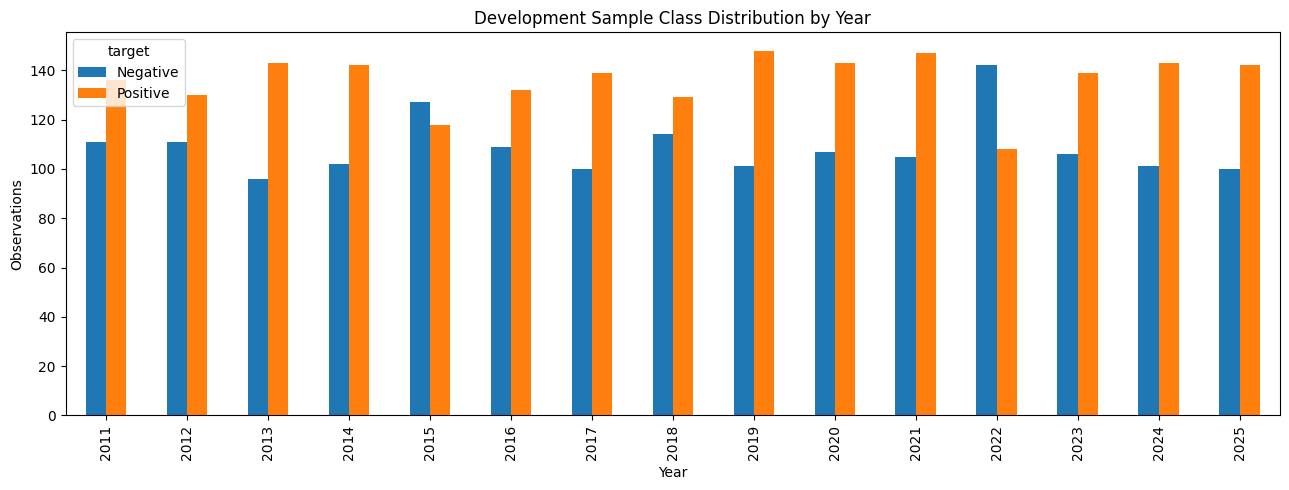

target,Negative,Positive
year,,
2021,105,147
2022,142,108
2023,106,139
2024,101,143
2025,100,142


In [ ]:
label_by_year = dev_labeled.assign(year=dev_labeled.index.year).groupby(["year", "target"]).size().unstack(fill_value=0)
label_by_year = label_by_year.rename(columns={0.0: "Negative", 1.0: "Positive"})

label_by_year.plot(kind="bar", figsize=(13, 5))
plt.title("Development Sample Class Distribution by Year")
plt.xlabel("Year")
plt.ylabel("Observations")
plt.tight_layout()
plt.show()

label_by_year.tail()

# 5. Feature Selection Funnel

## Stage 1 — Filter Methods

The filter stage removes features with excessive missingness, near-zero variance, and high pairwise correlation. This reduces redundancy before model-based selection.

In [ ]:
X_dev_raw = dev_labeled[candidate_features].copy()
y_dev = dev_labeled["target"].astype(int)

# Missingness filter.
missing_ratio = X_dev_raw.isnull().mean()
features_after_missing = missing_ratio[missing_ratio < 0.05].index.tolist()

# Variance filter.
variance = X_dev_raw[features_after_missing].var()
features_after_variance = variance[variance > 1e-10].index.tolist()

# Correlation filter.
corr = X_dev_raw[features_after_variance].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
features_dropped_corr = [col for col in upper.columns if any(upper[col] > CORRELATION_CUTOFF)]
features_after_corr = [c for c in features_after_variance if c not in features_dropped_corr]

print(f"Initial features: {len(candidate_features)}")
print(f"After missingness filter: {len(features_after_missing)}")
print(f"After variance filter: {len(features_after_variance)}")
print(f"After correlation filter: {len(features_after_corr)}")
print("Dropped by correlation:")
print(features_dropped_corr)

Initial features: 87
After missingness filter: 87
After variance filter: 87
After correlation filter: 58
Dropped by correlation:
['std_15', 'std_20', 'std_25', 'std_30', 'ret_sum_35', 'std_35', 'ret_sum_40', 'std_40', 'ret_sum_45', 'std_45', 'ret_sum_50', 'std_50', 'ret_sum_55', 'std_55', 'ret_sum_60', 'std_60', 'mom_10d', 'mom_20d', 'mom_60d', 'close_to_sma_10', 'close_to_sma_20', 'close_to_sma_50', 'close_to_sma_100', 'realized_vol_10d', 'realized_vol_20d', 'realized_vol_60d', 'parkinson_vol_10d', 'parkinson_vol_20d', 'quarter']


## Stage 2 — Filter Ranking by Mutual Information

Mutual information is used as a non-linear filter ranking. It is model-agnostic and can detect non-linear dependence between features and the class label.

This stage keeps the best-ranked features before wrapper and embedded selection.

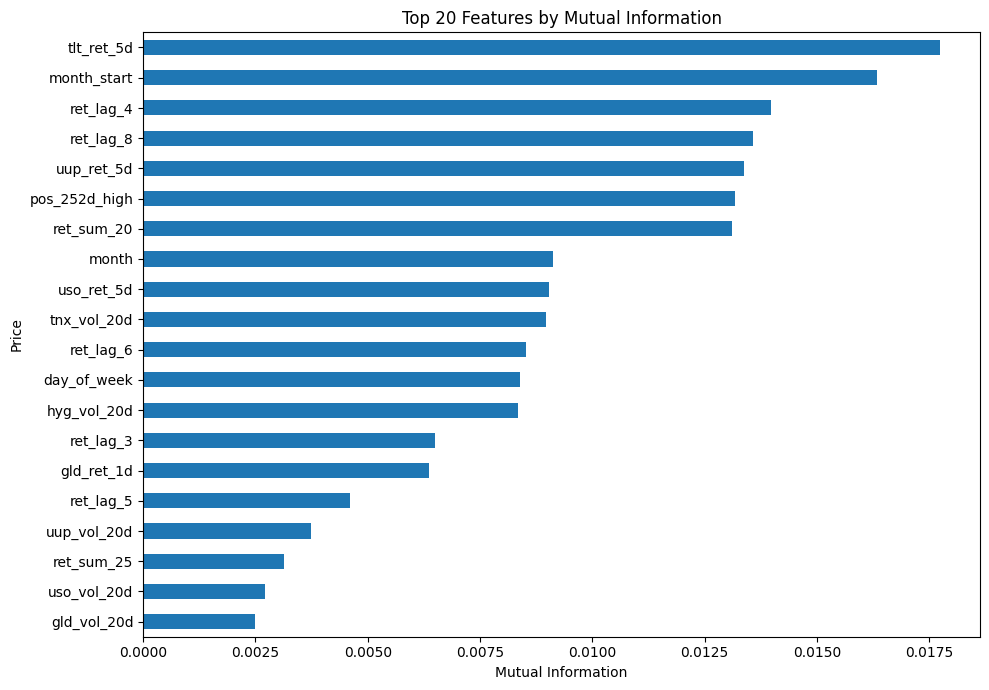

,mutual_information
Price,
tlt_ret_5d,0.017746
month_start,0.016330
ret_lag_4,0.013984
ret_lag_8,0.013568
uup_ret_5d,0.013368
pos_252d_high,0.013188
ret_sum_20,0.013114
month,0.009124
uso_ret_5d,0.009026


In [ ]:
X_filter = X_dev_raw[features_after_corr].dropna()
y_filter = y_dev.loc[X_filter.index]

mi = mutual_info_classif(X_filter, y_filter, random_state=RANDOM_STATE)
mi_scores = pd.Series(mi, index=X_filter.columns).sort_values(ascending=False)

top_mi_features = mi_scores.head(min(40, len(mi_scores))).index.tolist()

mi_scores.head(20).plot(kind="barh", figsize=(10, 7))
plt.gca().invert_yaxis()
plt.title("Top 20 Features by Mutual Information")
plt.xlabel("Mutual Information")
plt.tight_layout()
plt.show()

mi_scores.head(20).to_frame("mutual_information")

## Stage 3 — Wrapper Selection

A full RFECV process can be computationally expensive. For this exam-style implementation, the wrapper step uses expanding-window validation and evaluates incremental feature subsets ranked by mutual information.

The selected subset is the one producing the highest average ROC-AUC across time-series validation folds.

In [ ]:
def get_tscv_splits(X, n_splits=5):
    return TimeSeriesSplit(n_splits=n_splits, gap=1).split(X)

wrapper_rows = []

subset_sizes = [10, 15, 20, 25, 30, 35, 40]
subset_sizes = [s for s in subset_sizes if s <= len(top_mi_features)]

base_wrapper_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=30,
    subsample=0.8,
    random_state=RANDOM_STATE
)

X_wrapper_full = X_filter[top_mi_features]
y_wrapper = y_filter

for size in subset_sizes:
    subset = top_mi_features[:size]
    X_sub = X_wrapper_full[subset]

    aucs = []
    for train_idx, val_idx in get_tscv_splits(X_sub, n_splits=5):
        X_tr, X_va = X_sub.iloc[train_idx], X_sub.iloc[val_idx]
        y_tr, y_va = y_wrapper.iloc[train_idx], y_wrapper.iloc[val_idx]

        base_wrapper_model.fit(X_tr, y_tr)
        p = base_wrapper_model.predict_proba(X_va)[:, 1]
        aucs.append(roc_auc_score(y_va, p))

    wrapper_rows.append({
        "n_features": size,
        "mean_roc_auc": np.mean(aucs),
        "std_roc_auc": np.std(aucs),
    })

wrapper_results = pd.DataFrame(wrapper_rows).sort_values("mean_roc_auc", ascending=False)
display(wrapper_results)

best_wrapper_size = int(wrapper_results.iloc[0]["n_features"])
wrapper_features = top_mi_features[:best_wrapper_size]

print(f"Selected wrapper size: {best_wrapper_size}")
print(wrapper_features)

,n_features,mean_roc_auc,std_roc_auc
1,15,0.511246,0.026026
0,10,0.506795,0.026883
2,20,0.501840,0.025201
4,30,0.500182,0.024806
6,40,0.499761,0.016028
3,25,0.499578,0.024223
5,35,0.497749,0.021699


Selected wrapper size: 15
['tlt_ret_5d', 'month_start', 'ret_lag_4', 'ret_lag_8', 'uup_ret_5d', 'pos_252d_high', 'ret_sum_20', 'month', 'uso_ret_5d', 'tnx_vol_20d', 'ret_lag_6', 'day_of_week', 'hyg_vol_20d', 'ret_lag_3', 'gld_ret_1d']


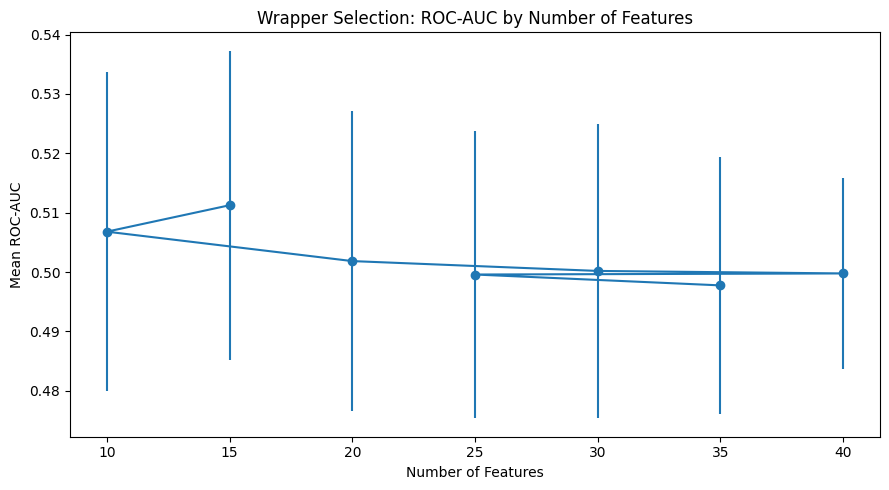

In [ ]:
plt.figure(figsize=(9, 5))
plt.errorbar(wrapper_results["n_features"], wrapper_results["mean_roc_auc"], yerr=wrapper_results["std_roc_auc"], marker="o")
plt.title("Wrapper Selection: ROC-AUC by Number of Features")
plt.xlabel("Number of Features")
plt.ylabel("Mean ROC-AUC")
plt.tight_layout()
plt.show()

## Stage 4 — Embedded Feature Selection

The embedded step uses model-based feature importance from XGBoost if available. If XGBoost is unavailable, the notebook uses the classic Gradient Boosting model.

The final feature subset is capped to maintain parsimony and reduce overfitting.

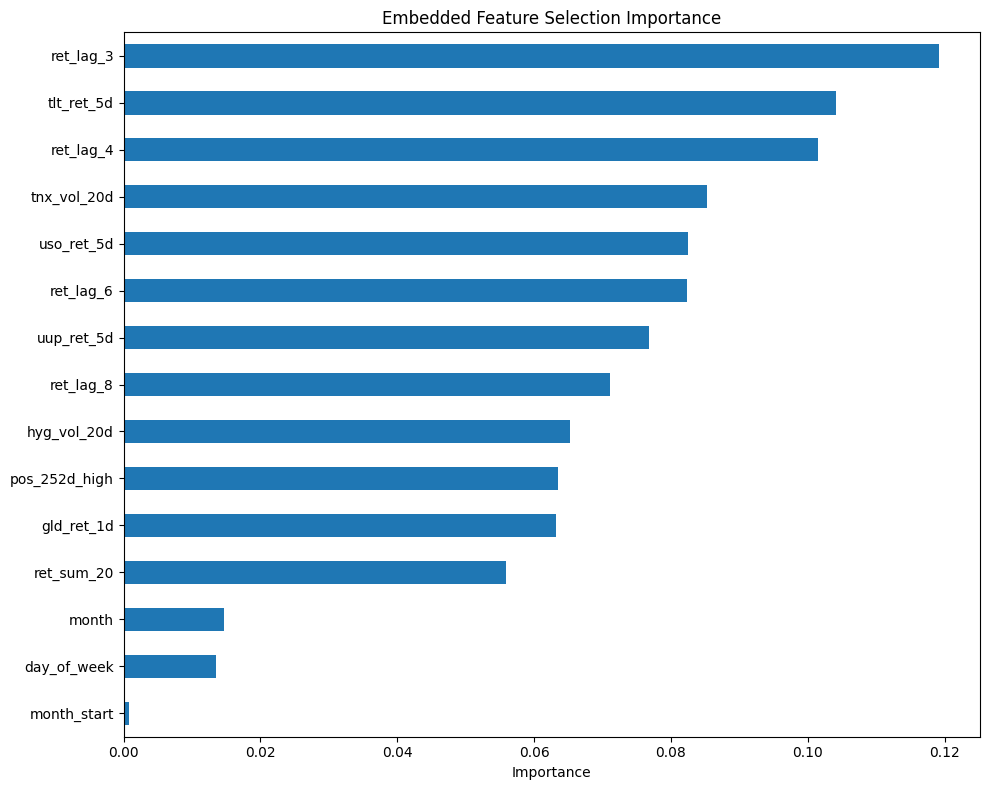

Final number of selected features: 15


['ret_lag_3',
 'tlt_ret_5d',
 'ret_lag_4',
 'tnx_vol_20d',
 'uso_ret_5d',
 'ret_lag_6',
 'uup_ret_5d',
 'ret_lag_8',
 'hyg_vol_20d',
 'pos_252d_high',
 'gld_ret_1d',
 'ret_sum_20',
 'month',
 'day_of_week',
 'month_start']

In [ ]:
X_emb = X_filter[wrapper_features]
y_emb = y_filter

if XGBClassifier is not None:
    embedded_model = XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.80,
        colsample_bytree=0.80,
        reg_alpha=1.0,
        reg_lambda=5.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
else:
    embedded_model = GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=30,
        subsample=0.80,
        random_state=RANDOM_STATE,
    )

sample_weights = compute_sample_weight(class_weight="balanced", y=y_emb)
embedded_model.fit(X_emb, y_emb, sample_weight=sample_weights if XGBClassifier is not None else None)

if hasattr(embedded_model, "feature_importances_"):
    embedded_importance = pd.Series(embedded_model.feature_importances_, index=wrapper_features).sort_values(ascending=False)
else:
    perm = permutation_importance(embedded_model, X_emb, y_emb, n_repeats=5, random_state=RANDOM_STATE)
    embedded_importance = pd.Series(perm.importances_mean, index=wrapper_features).sort_values(ascending=False)

final_features = embedded_importance.head(min(MAX_FEATURES_AFTER_FUNNEL, len(embedded_importance))).index.tolist()

embedded_importance.head(25).sort_values().plot(kind="barh", figsize=(10, 8))
plt.title("Embedded Feature Selection Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(f"Final number of selected features: {len(final_features)}")
final_features

## Final Selected Features

The selected features are obtained after combining:

1. Missingness and variance filters  
2. Correlation filtering  
3. Mutual information ranking  
4. Wrapper validation using expanding-window splits  
5. Embedded importance from a gradient boosting estimator

In [ ]:
final_feature_table = pd.DataFrame({
    "selected_feature": final_features,
    "embedded_importance": embedded_importance.loc[final_features].values
})

final_feature_table

,selected_feature,embedded_importance
0,ret_lag_3,0.119214
1,tlt_ret_5d,0.104159
2,ret_lag_4,0.101499
3,tnx_vol_20d,0.085288
4,uso_ret_5d,0.082568
5,ret_lag_6,0.082410
6,uup_ret_5d,0.076793
7,ret_lag_8,0.071075
8,hyg_vol_20d,0.065259
9,pos_252d_high,0.063541


# Question C — Model Building, Tuning and Evaluation

This section builds and compares three gradient boosting classifiers:

1. Classic Gradient Boosting  
2. XGBoost  
3. LightGBM  

The estimator choice and number of tuned hyperparameters are design decisions. The notebook uses time-series cross-validation to tune each available estimator.

## Evaluation Functions

In [ ]:
def sharpe_ratio(returns, periods_per_year=252):
    returns = returns.dropna()
    if len(returns) == 0 or returns.std() == 0:
        return np.nan
    return np.sqrt(periods_per_year) * returns.mean() / returns.std()

def max_drawdown(returns):
    equity = (1 + returns.fillna(0)).cumprod()
    peak = equity.cummax()
    dd = equity / peak - 1
    return dd.min()

def profit_factor(returns):
    gains = returns[returns > 0].sum()
    losses = returns[returns < 0].sum()
    if losses == 0:
        return np.nan
    return gains / abs(losses)

def evaluate_classifier(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba) if len(np.unique(y_true)) == 2 else np.nan,
    }

def probability_to_signal(proba_up, threshold=0.55):
    signal = pd.Series(0, index=proba_up.index, dtype=float)
    signal[proba_up > threshold] = 1
    signal[proba_up < 1 - threshold] = -1
    return signal

def evaluate_strategy(actual_returns, proba_up, threshold=0.55):
    proba_up = pd.Series(proba_up, index=actual_returns.index)
    signal = probability_to_signal(proba_up, threshold=threshold)
    strategy_returns = signal * actual_returns

    return {
        "strategy_return": (1 + strategy_returns.fillna(0)).prod() - 1,
        "buy_hold_return": (1 + actual_returns.fillna(0)).prod() - 1,
        "sharpe": sharpe_ratio(strategy_returns),
        "max_drawdown": max_drawdown(strategy_returns),
        "hit_ratio": (strategy_returns[strategy_returns != 0] > 0).mean(),
        "profit_factor": profit_factor(strategy_returns),
        "active_days_pct": (signal != 0).mean(),
        "turnover": signal.diff().abs().fillna(0).mean(),
    }, signal, strategy_returns

## Hyperparameter Tuning with TimeSeriesSplit

Random search is used instead of an exhaustive grid because it is more efficient and better suited to a short exam timeline. The scoring metric is ROC-AUC.

In [ ]:
X_train_dev = dev_labeled[final_features].copy()
y_train_dev = dev_labeled["target"].astype(int)

tscv = TimeSeriesSplit(n_splits=5, gap=1)

model_spaces = {}

model_spaces["Classic_GBM"] = (
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    {
        "n_estimators": [100, 200, 300],
        "learning_rate": [0.02, 0.03, 0.05, 0.08],
        "max_depth": [2, 3, 4],
        "min_samples_leaf": [10, 20, 30, 50],
        "subsample": [0.7, 0.8, 1.0],
    }
)

if XGBClassifier is not None:
    model_spaces["XGBoost"] = (
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        {
            "n_estimators": [150, 250, 400],
            "learning_rate": [0.02, 0.03, 0.05, 0.08],
            "max_depth": [2, 3, 4],
            "subsample": [0.7, 0.8, 1.0],
            "colsample_bytree": [0.7, 0.8, 1.0],
            "reg_alpha": [0.0, 0.5, 1.0],
            "reg_lambda": [1.0, 3.0, 5.0],
        }
    )

if LGBMClassifier is not None:
    model_spaces["LightGBM"] = (
        LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
        {
            "n_estimators": [150, 250, 400],
            "learning_rate": [0.02, 0.03, 0.05, 0.08],
            "max_depth": [2, 3, 4],
            "num_leaves": [4, 8, 16],
            "subsample": [0.7, 0.8, 1.0],
            "colsample_bytree": [0.7, 0.8, 1.0],
            "reg_alpha": [0.0, 0.5, 1.0],
            "reg_lambda": [1.0, 3.0, 5.0],
        }
    )

best_models = {}
tuning_rows = []

for name, (estimator, param_dist) in model_spaces.items():
    print(f"Tuning {name}...")

    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_dist,
        n_iter=20,
        scoring="roc_auc",
        cv=tscv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=0,
    )

    search.fit(X_train_dev, y_train_dev)

    best_models[name] = search.best_estimator_
    tuning_rows.append({
        "model": name,
        "best_cv_roc_auc": search.best_score_,
        "best_params": search.best_params_,
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("best_cv_roc_auc", ascending=False)
tuning_results

Tuning Classic_GBM...


,model,best_cv_roc_auc,best_params
0,Classic_GBM,0.515081,"{'subsample': 1.0, 'n_estimators': 200, 'min_s..."


## Expanding-Window Walk-Forward Validation

The tuned models are evaluated using annual expanding-window validation from 2017 to 2025. This provides a stability check across different market regimes.

In [ ]:
wf_rows = []

for val_year in range(2017, 2026):
    train_end = f"{val_year - 1}-12-31"
    val_start = f"{val_year}-01-01"
    val_end = f"{val_year}-12-31"

    train = dev_labeled[dev_labeled.index <= train_end].copy()
    val = dev_labeled[(dev_labeled.index >= val_start) & (dev_labeled.index <= val_end)].copy()

    X_tr = train[final_features]
    y_tr = train["target"].astype(int)

    X_va = val[final_features]
    y_va = val["target"].astype(int)

    for name, model in best_models.items():
        model.fit(X_tr, y_tr)
        pred = model.predict(X_va)
        proba = model.predict_proba(X_va)[:, 1]

        cls = evaluate_classifier(y_va, pred, proba)
        strat, _, _ = evaluate_strategy(val["fwd_simple_return"], pd.Series(proba, index=val.index), threshold=0.55)

        wf_rows.append({
            "model": name,
            "validation_year": val_year,
            **cls,
            **strat,
        })

wf = pd.DataFrame(wf_rows)

wf_summary = wf.groupby("model").agg({
    "accuracy": "mean",
    "balanced_accuracy": "mean",
    "precision": "mean",
    "recall": "mean",
    "f1": "mean",
    "roc_auc": "mean",
    "strategy_return": "mean",
    "buy_hold_return": "mean",
    "sharpe": "mean",
    "max_drawdown": "mean",
    "hit_ratio": "mean",
    "profit_factor": "mean",
    "active_days_pct": "mean",
    "turnover": "mean",
}).sort_values(["roc_auc", "sharpe"], ascending=False)

wf_summary.round(4)

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,strategy_return,buy_hold_return,sharpe,max_drawdown,hit_ratio,profit_factor,active_days_pct,turnover
model,,,,,,,,,,,,,,
Classic_GBM,0.5233,0.5013,0.5616,0.7503,0.6345,0.5135,0.0289,0.1626,0.5878,-0.1351,0.5321,1.1592,0.6731,0.5326


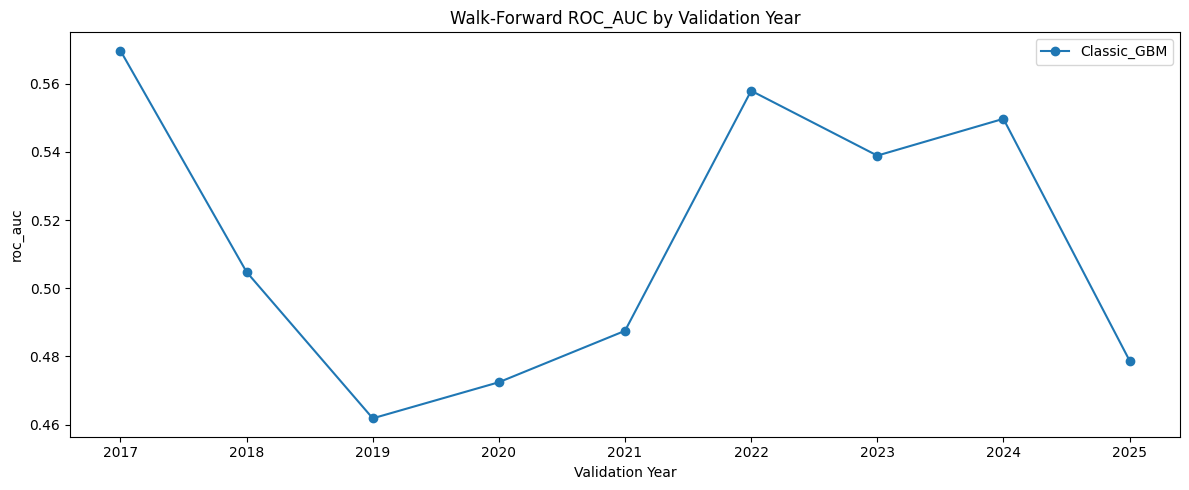

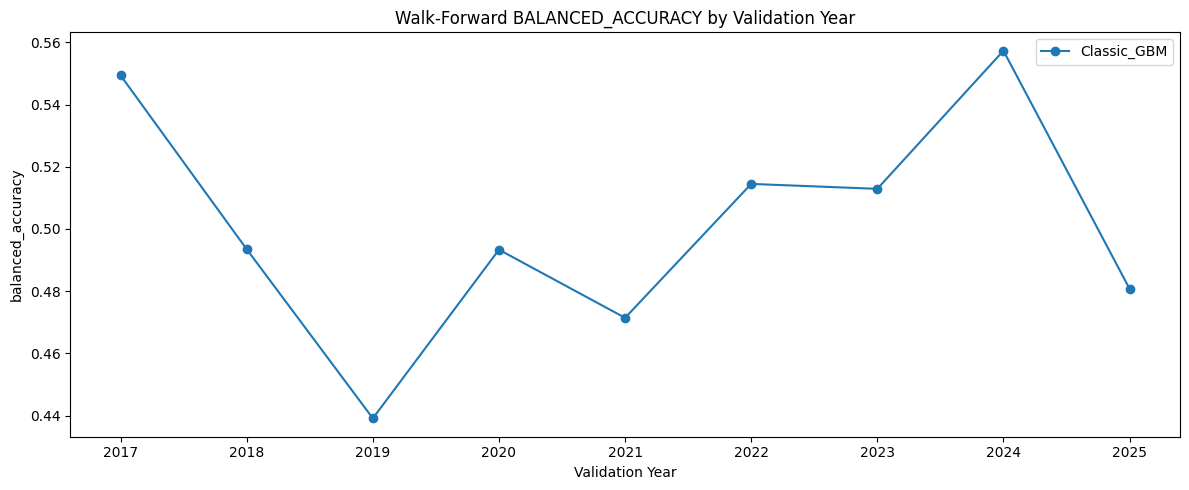

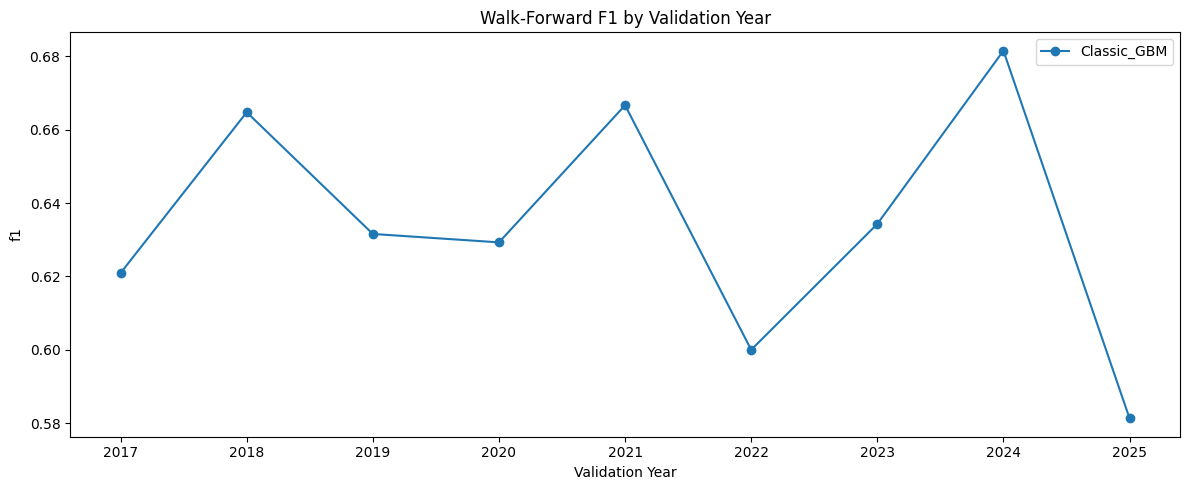

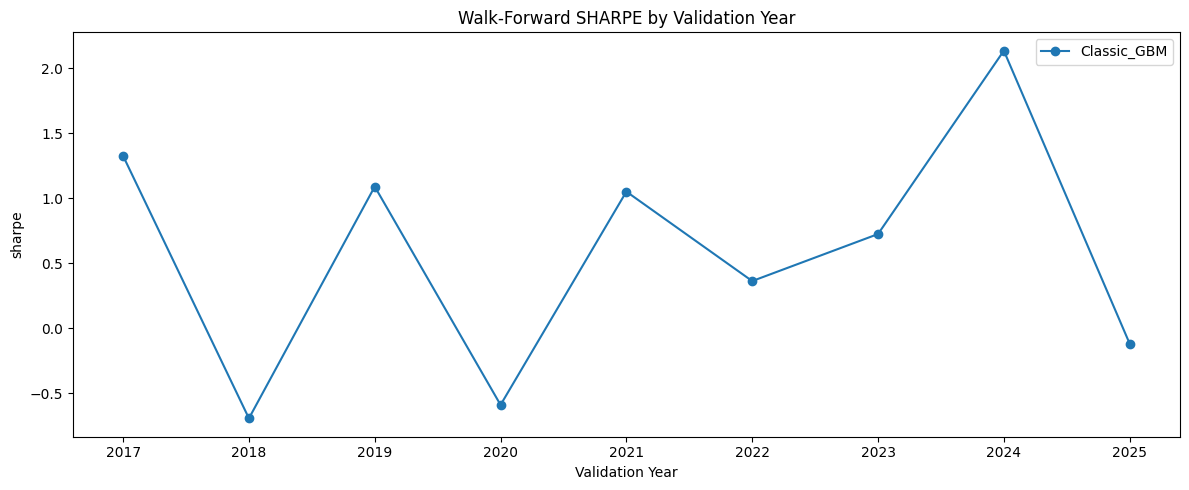

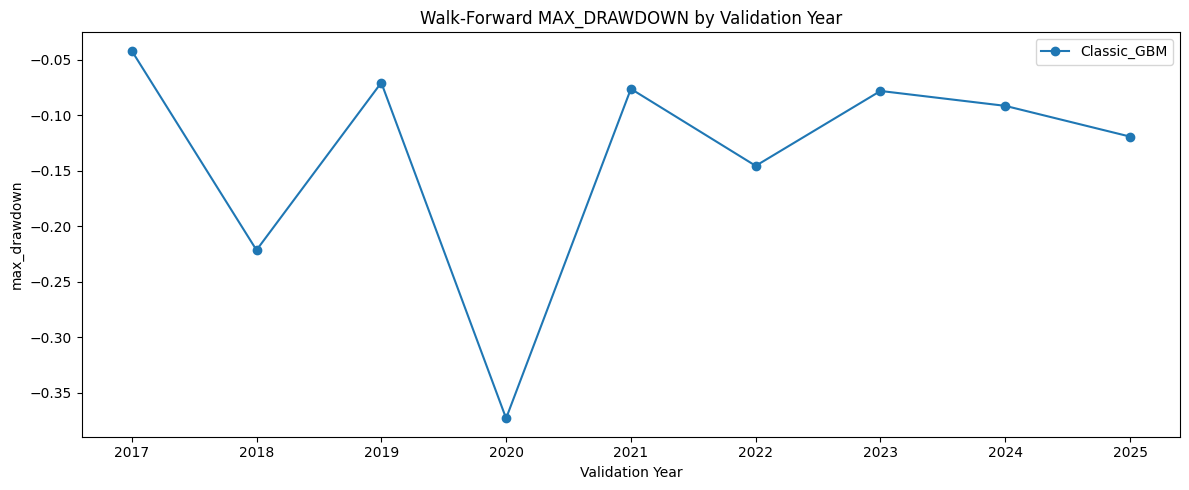

In [ ]:
for metric in ["roc_auc", "balanced_accuracy", "f1", "sharpe", "max_drawdown"]:
    pivot = wf.pivot(index="validation_year", columns="model", values=metric)
    plt.figure(figsize=(12, 5))
    for col in pivot.columns:
        plt.plot(pivot.index, pivot[col], marker="o", label=col)
    plt.title(f"Walk-Forward {metric.upper()} by Validation Year")
    plt.xlabel("Validation Year")
    plt.ylabel(metric)
    plt.legend()
    plt.tight_layout()
    plt.show()

## Final Out-of-Sample Test: Q1 2026

Each tuned model is retrained on all eligible data from 2010 to 2025, then tested on Q1 2026. This is the final out-of-sample evaluation.

In [ ]:
train_final = dev_labeled.copy()
oos_all = data_model[(data_model.index >= OOS_START) & (data_model.index <= OOS_END)].copy()
oos_eval = oos_all.dropna(subset=["target"]).copy()

X_final = train_final[final_features]
y_final = train_final["target"].astype(int)

X_oos_eval = oos_eval[final_features]
y_oos = oos_eval["target"].astype(int)

X_oos_all = oos_all[final_features]

oos_rows = []
oos_results = {}

for name, model in best_models.items():
    print("=" * 80)
    print(f"Final model: {name}")

    model.fit(X_final, y_final)

    pred_eval = model.predict(X_oos_eval)
    proba_eval = model.predict_proba(X_oos_eval)[:, 1]

    cls = evaluate_classifier(y_oos, pred_eval, proba_eval)

    proba_all = pd.Series(model.predict_proba(X_oos_all)[:, 1], index=oos_all.index)
    strat, signal, strat_returns = evaluate_strategy(
        oos_all["fwd_simple_return"],
        proba_all,
        threshold=0.55,
    )

    oos_rows.append({
        "model": name,
        **cls,
        **strat,
    })

    oos_results[name] = {
        "model": model,
        "pred_eval": pd.Series(pred_eval, index=oos_eval.index),
        "proba_eval": pd.Series(proba_eval, index=oos_eval.index),
        "proba_all": proba_all,
        "signal": signal,
        "strategy_returns": strat_returns,
        "actual_returns": oos_all["fwd_simple_return"],
    }

    print(classification_report(y_oos, pred_eval, target_names=["Negative", "Positive"]))
    cm = confusion_matrix(y_oos, pred_eval)
    display(pd.DataFrame(cm, index=["Actual Negative", "Actual Positive"], columns=["Pred Negative", "Pred Positive"]))

oos_summary = pd.DataFrame(oos_rows).set_index("model").sort_values(["roc_auc", "sharpe"], ascending=False)
oos_summary.round(4)

Final model: Classic_GBM
              precision    recall  f1-score   support

    Negative       0.44      0.13      0.20        31
    Positive       0.45      0.81      0.58        27

    accuracy                           0.45        58
   macro avg       0.45      0.47      0.39        58
weighted avg       0.45      0.45      0.38        58



,Pred Negative,Pred Positive
Actual Negative,4,27
Actual Positive,5,22


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,strategy_return,buy_hold_return,sharpe,max_drawdown,hit_ratio,profit_factor,active_days_pct,turnover
model,,,,,,,,,,,,,,
Classic_GBM,0.4483,0.4719,0.449,0.8148,0.5789,0.4922,-0.0495,-0.0455,-1.5429,-0.1217,0.4222,0.7459,0.75,0.5


## ROC Curves, Precision-Recall Curves, and Confusion Matrices

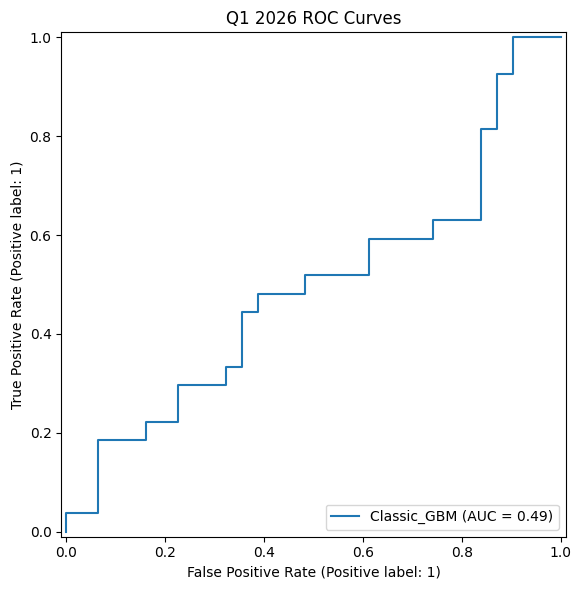

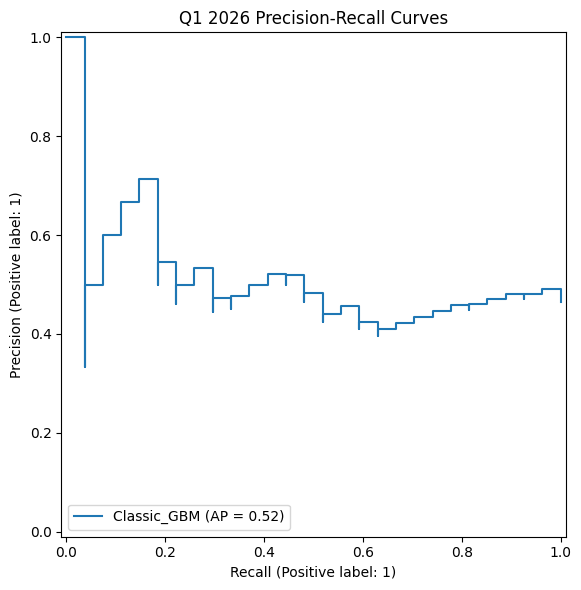

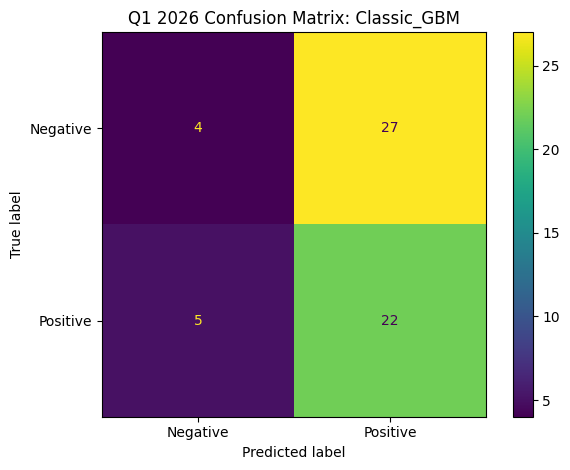

In [ ]:
plt.figure(figsize=(8, 6))
for name, res in oos_results.items():
    RocCurveDisplay.from_predictions(
        y_oos,
        res["proba_eval"].loc[y_oos.index],
        name=name,
        ax=plt.gca(),
    )
plt.title("Q1 2026 ROC Curves")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name, res in oos_results.items():
    PrecisionRecallDisplay.from_predictions(
        y_oos,
        res["proba_eval"].loc[y_oos.index],
        name=name,
        ax=plt.gca(),
    )
plt.title("Q1 2026 Precision-Recall Curves")
plt.tight_layout()
plt.show()

for name, res in oos_results.items():
    ConfusionMatrixDisplay.from_predictions(
        y_oos,
        res["pred_eval"].loc[y_oos.index],
        display_labels=["Negative", "Positive"]
    )
    plt.title(f"Q1 2026 Confusion Matrix: {name}")
    plt.tight_layout()
    plt.show()

## Optional Backtest of Predicted Signals

The exam describes backtesting as an optional add-on. Here, a simple strategy is evaluated:

- Long SPY if \(P(y=1) > 55\%\)
- Short SPY if \(P(y=1) < 45\%\)
- Flat otherwise

Transaction costs are not included, so these results are indicative rather than directly tradable.

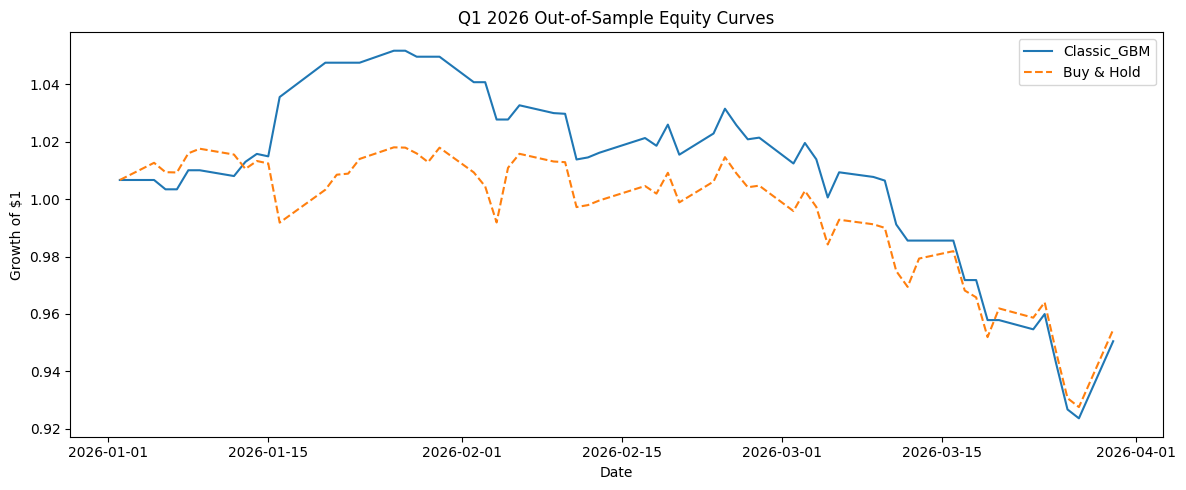

In [ ]:
plt.figure(figsize=(12, 5))
for name, res in oos_results.items():
    equity = (1 + res["strategy_returns"].fillna(0)).cumprod()
    plt.plot(equity.index, equity.values, label=name)

buy_hold = (1 + next(iter(oos_results.values()))["actual_returns"].fillna(0)).cumprod()
plt.plot(buy_hold.index, buy_hold.values, linestyle="--", label="Buy & Hold")

plt.title("Q1 2026 Out-of-Sample Equity Curves")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
monthly_tables = {}

for name, res in oos_results.items():
    tmp = pd.DataFrame({
        "actual_forward_return": oos_all["fwd_simple_return"],
        "prob_up": res["proba_all"],
        "signal": res["signal"],
        "strategy_return": res["strategy_returns"],
    }).dropna()

    tmp["month"] = tmp.index.to_period("M")

    monthly = tmp.groupby("month").agg({
        "actual_forward_return": "sum",
        "strategy_return": "sum",
        "signal": lambda x: (x != 0).mean(),
        "prob_up": "mean",
    }).rename(columns={
        "actual_forward_return": "buy_hold_return_sum",
        "strategy_return": "strategy_return_sum",
        "signal": "active_days_pct",
        "prob_up": "avg_prob_up",
    })

    monthly_tables[name] = monthly
    print(f"\n{name}")
    display(monthly.round(4))


Classic_GBM


,buy_hold_return_sum,strategy_return_sum,active_days_pct,avg_prob_up
month,,,,
2026-01,0.0182,0.0487,0.5500,0.5434
2026-02,-0.0124,-0.0268,0.8947,0.6079
2026-03,-0.0498,-0.0706,0.8095,0.5802


## Feature Importance of Final Models

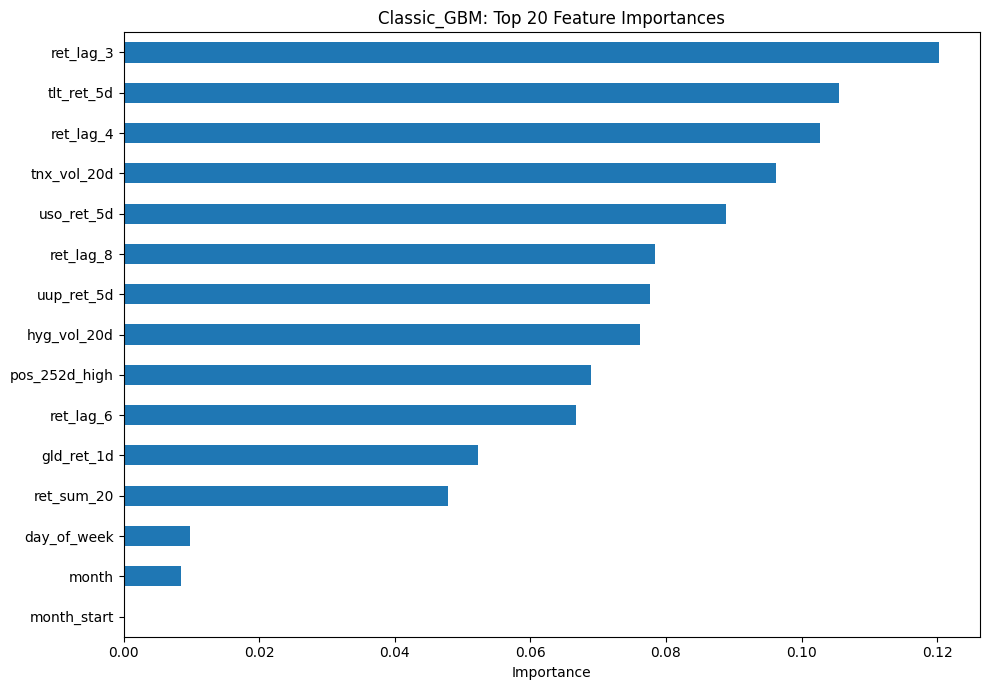

,importance
ret_lag_3,0.120315
tlt_ret_5d,0.105534
ret_lag_4,0.102755
tnx_vol_20d,0.096280
uso_ret_5d,0.088919
ret_lag_8,0.078382
uup_ret_5d,0.077598
hyg_vol_20d,0.076226
pos_252d_high,0.068875
ret_lag_6,0.066739


In [ ]:
for name, res in oos_results.items():
    model = res["model"]
    if hasattr(model, "feature_importances_"):
        imp = pd.Series(model.feature_importances_, index=final_features).sort_values(ascending=False)
        plt.figure(figsize=(10, 7))
        imp.head(20).sort_values().plot(kind="barh")
        plt.title(f"{name}: Top 20 Feature Importances")
        plt.xlabel("Importance")
        plt.tight_layout()
        plt.show()
        display(imp.head(20).to_frame("importance"))

# Model Selection and Discussion

The preferred model should not be selected by accuracy alone. The final decision should consider:

1. ROC-AUC and balanced accuracy  
2. Confusion matrix behavior  
3. Precision, recall, and F1-score  
4. Walk-forward stability  
5. Q1 2026 out-of-sample performance  
6. Backtested signal performance  
7. Feature importance plausibility  

If one model has the highest ROC-AUC but materially worse drawdown or unstable validation behavior, it may not be the best practical model.

In [ ]:
print("Tuning results:")
display(tuning_results)

print("Walk-forward summary:")
display(wf_summary.round(4))

print("Q1 2026 out-of-sample summary:")
display(oos_summary.round(4))

best_by_auc = oos_summary["roc_auc"].idxmax()
best_by_sharpe = oos_summary["sharpe"].idxmax()

print(f"Best model by Q1 2026 ROC-AUC: {best_by_auc}")
print(f"Best model by Q1 2026 Sharpe: {best_by_sharpe}")

Tuning results:


,model,best_cv_roc_auc,best_params
0,Classic_GBM,0.515081,"{'subsample': 1.0, 'n_estimators': 200, 'min_s..."


Walk-forward summary:


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,strategy_return,buy_hold_return,sharpe,max_drawdown,hit_ratio,profit_factor,active_days_pct,turnover
model,,,,,,,,,,,,,,
Classic_GBM,0.5233,0.5013,0.5616,0.7503,0.6345,0.5135,0.0289,0.1626,0.5878,-0.1351,0.5321,1.1592,0.6731,0.5326


Q1 2026 out-of-sample summary:


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,strategy_return,buy_hold_return,sharpe,max_drawdown,hit_ratio,profit_factor,active_days_pct,turnover
model,,,,,,,,,,,,,,
Classic_GBM,0.4483,0.4719,0.449,0.8148,0.5789,0.4922,-0.0495,-0.0455,-1.5429,-0.1217,0.4222,0.7459,0.75,0.5


Best model by Q1 2026 ROC-AUC: Classic_GBM
Best model by Q1 2026 Sharpe: Classic_GBM


# Conclusion

This notebook implements a full CQF-style machine-learning workflow for predicting positive market moves in SPY using gradient boosting. The analysis includes:

- Entropy explanation for classification
- Feature engineering from technical, volatility, volume, calendar, and cross-asset data
- A feature-selection funnel combining filter, wrapper, and embedded methods
- Hyperparameter tuning using time-series cross-validation
- Model evaluation using ROC-AUC, confusion matrices, and classification reports
- Optional backtesting of predicted trading signals

The final report should discuss the actual numerical results obtained after running the notebook and justify the selected final model using both statistical and economic criteria.

# References

- Chen, T. and Guestrin, C. (2016) 'XGBoost: A scalable tree boosting system', *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, pp. 785–794.
- Friedman, J.H. (2001) 'Greedy function approximation: A gradient boosting machine', *Annals of Statistics*, 29(5), pp. 1189–1232.
- Ke, G. et al. (2017) 'LightGBM: A highly efficient gradient boosting decision tree', *Advances in Neural Information Processing Systems*, 30.
- López de Prado, M. (2018) *Advances in Financial Machine Learning*. Hoboken: Wiley.
- Hastie, T., Tibshirani, R. and Friedman, J. (2009) *The Elements of Statistical Learning*. 2nd edn. New York: Springer.
- Yahoo Finance. Historical market data for SPY and related exchange-traded funds.

# Save Output Files

In [ ]:
tuning_results.to_csv(f"{OUTPUT_PREFIX}_tuning_results.csv", index=False)
wf.to_csv(f"{OUTPUT_PREFIX}_walk_forward_results.csv", index=False)
wf_summary.to_csv(f"{OUTPUT_PREFIX}_walk_forward_summary.csv")
oos_summary.to_csv(f"{OUTPUT_PREFIX}_q1_2026_oos_summary.csv")
final_feature_table.to_csv(f"{OUTPUT_PREFIX}_final_features.csv", index=False)

data_model[final_features + ["target", "fwd_log_return", "fwd_simple_return"]].to_csv(
    f"{OUTPUT_PREFIX}_model_dataset.csv"
)

print("Saved output CSV files.")

Saved output CSV files.


In [ ]:
wf_summary.to_latex(
    "wf_summary.tex",
    float_format="%.4f",
    caption="Walk-forward validation results",
    label="tab:wf"
)